<a href="https://colab.research.google.com/github/jvcobos5-design/diplomado-m6-cobos-jair/blob/main/talleres/clase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- m6:clase=2;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 2 — Bagging, random forest, boosting, SHAP y probabilidad bayesiana
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · jueves 12-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas de demostración ya están completas.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas.
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** (no la plantilla) → ruta `talleres/clase2.ipynb` → mensaje `Clase 2`.

> Datos: app de pagos móviles **PagoYa** (ficticia, simulada con fines didácticos), los mismos de la Clase 1.

## 0. Preparación y registro (Checkpoint 0)

In [1]:
import os, urllib.request                                   # utilidades para descargar archivos
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):                          # descarga las funciones del curso una sola vez
    urllib.request.urlretrieve(URL, 'curso.py')
import curso                                                # API simulada, datos limpios y checkpoints
import time, warnings                                       # medición de tiempos y avisos
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd                            # cálculo numérico y tablas
import matplotlib.pyplot as plt                             # gráficos
from scipy import stats                                     # distribución beta (sección 2.4)
from sklearn.model_selection import train_test_split        # partición entrenamiento / prueba
from sklearn.tree import DecisionTreeClassifier             # árbol individual (punto de partida)
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score         # exactitud balanceada
from xgboost import XGBClassifier                           # boosting XGBoost
from lightgbm import LGBMClassifier                         # boosting LightGBM
import shap                                                 # explicabilidad (valores de Shapley)
plt.rcParams['figure.figsize'] = (10, 3.6)
ba = lambda m, X_, y_: balanced_accuracy_score(y_, m.predict(X_))   # atajo: exactitud balanceada
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


### ✏️ Checkpoint 0 · ⏱ 2 min
Registre su nombre como **'Apellido Nombre'** e indique la **clase 2**.

In [3]:
curso.registrar('Jair Cobos', clase="2")          # ✏️ su apellido y nombre, y el número de esta clase

Estudiante registrado: Jair Cobos
Clase 2
✅ Checkpoint 0 correcto · código K0-8C2A


In [4]:
df = curso.cargar_pagoya_limpio()                           # misma API y limpieza de la Clase 1
X, y = df[curso.X_COLS], df['fraude']                       # 8 variables numéricas y objetivo 0/1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)       # la MISMA partición de la Clase 1
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape)

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
Entrenamiento: (2097, 8) · Prueba: (899, 8)


---
## 2.1 Bagging y random forest: promediar árboles para reducir la varianza
Ayer vimos que dos árboles entrenados con muestras distintas discrepan en ~8 % de los casos. **Bagging** (*bootstrap aggregating*): entrenar muchos árboles, cada uno con una muestra bootstrap, y **votar**. **Random forest** agrega un truco: en cada división, cada árbol solo mira un **subconjunto aleatorio de variables**, para que los árboles se parezcan menos entre sí.

In [5]:
arbol = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_train, y_train)
bag = BaggingClassifier(DecisionTreeClassifier(class_weight='balanced'),
                        n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)   # 100 árboles bootstrap
print('Árbol individual :', round(ba(arbol, X_test, y_test), 3))
print('Bagging (100)    :', round(ba(bag, X_test, y_test), 3))

Árbol individual : 0.786
Bagging (100)    : 0.816


El **error out-of-bag (OOB)**: cada muestra bootstrap deja fuera ~37 % de las filas. Cada árbol se evalúa en las filas que **no** vio: es una validación **gratuita**, sin separar datos.

### ✏️ Checkpoint 1 · ⏱ 5 min
Entrene un **random forest** con `n_estimators=200`, `min_samples_leaf=5`, `oob_score=True`, `class_weight='balanced'` y `random_state=42`. Lea el puntaje OOB.

In [8]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, oob_score=True,
                            class_weight='balanced', random_state=42, n_jobs=-1)   # ✏️
rf.fit(X_train, y_train)
print('Exactitud OOB:', round(rf.oob_score_, 4), '· exactitud balanceada en prueba:', round(ba(rf, X_test, y_test), 3))
curso.checkpoint(1, rf.oob_score_)

Exactitud OOB: 0.9557 · exactitud balanceada en prueba: 0.891
✅ Checkpoint 1 correcto · código K1-9C92


---
## 2.2 Boosting: árboles en serie que corrigen errores
**Boosting** entrena árboles **pequeños uno tras otro**: cada nuevo árbol se ajusta a los errores (gradiente) de los anteriores. La **tasa de aprendizaje** decide cuánto aporta cada árbol: pequeña = más árboles, pero mejor generalización. **Early stopping** detiene el entrenamiento cuando el error en un conjunto de **validación** deja de bajar.

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)   # validación SALE del entrenamiento
peso = (y_tr == 0).sum() / (y_tr == 1).sum()                # ~11 no fraudes por cada fraude
for lr in [0.3, 0.05]:                                      # dos tasas de aprendizaje
    m = XGBClassifier(n_estimators=1000, learning_rate=lr, max_depth=3, early_stopping_rounds=30,
                      scale_pos_weight=peso, eval_metric='logloss', random_state=42)
    m.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)   # se detiene si 30 rondas no mejoran
    print(f'learning_rate={lr}: se detuvo en {m.best_iteration} árboles · exactitud balanceada {ba(m, X_test, y_test):.3f}')

learning_rate=0.3: se detuvo en 92 árboles · exactitud balanceada 0.899
learning_rate=0.05: se detuvo en 387 árboles · exactitud balanceada 0.904


### ✏️ Checkpoint 2 · ⏱ 5 min
Entrene el **XGBoost** con `learning_rate=0.05`, `max_depth=3` y `early_stopping_rounds=30`, usando `eval_set=[(X_val, y_val)]`.

In [9]:
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, early_stopping_rounds=30,
                    scale_pos_weight=peso, eval_metric='logloss', random_state=42)   # ✏️
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
acc_xgb = ba(xgb, X_test, y_test)
print('Árboles:', xgb.best_iteration, '· exactitud balanceada:', round(acc_xgb, 4))
curso.checkpoint(2, acc_xgb)

Árboles: 387 · exactitud balanceada: 0.9039
✅ Checkpoint 2 correcto · código K2-AA00


### ✏️ Checkpoint 3 · ⏱ 4 min
Entrene **LightGBM** con `n_estimators=300`, `learning_rate=0.05`, `num_leaves=15`, `class_weight='balanced'`, `random_state=42` y `verbose=-1`.

In [10]:
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                      class_weight='balanced', random_state=42, verbose=-1)   # ✏️
lgbm.fit(X_train, y_train)
acc_lgbm = ba(lgbm, X_test, y_test)
print('Exactitud balanceada LightGBM:', round(acc_lgbm, 4))
curso.checkpoint(3, acc_lgbm)

Exactitud balanceada LightGBM: 0.8903
✅ Checkpoint 3 correcto · código K3-057D


In [11]:
X_big = pd.concat([X_train] * 20, ignore_index=True)        # ~42 mil filas para medir tiempos
y_big = pd.concat([y_train] * 20, ignore_index=True)
modelos = {'GradientBoosting (sklearn)': GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42),
           'XGBoost (hist)': XGBClassifier(n_estimators=100, max_depth=3, tree_method='hist', random_state=42),
           'LightGBM': LGBMClassifier(n_estimators=100, num_leaves=8, random_state=42, verbose=-1)}
for nombre, m in modelos.items():                           # 100 árboles cada uno, mismos datos
    t = time.perf_counter(); m.fit(X_big, y_big)
    print(f'{nombre:<27} {time.perf_counter() - t:6.2f} s')

GradientBoosting (sklearn)   11.48 s
XGBoost (hist)                1.64 s
LightGBM                      1.04 s


### 💬 Pregunta 1
Bagging/random forest y boosting combinan muchos árboles. ¿Qué problema ataca cada uno (varianza o sesgo) y por qué el boosting necesita early stopping?

**Respuesta:**

* Baggin y Random Stopping atacan principalmente a la varianza ,  ya que realiza promedios de multiples arboles. Reduciendo la variabilidad global y el sobreajuste del modelo.

* Por otro lado Boosting ataca al problema del sesgo, dada la forma de entrenamiento secuencial de los árboles, donde el entrenamiento recursivo corrige los errores del anterior, mejorando el ajsute del modelo.

* Sin emabrgo, boosting necesita early stopping porque puede sobreajustarse al añadir mas arboles cuando corrige los errores residuales.

---
## 2.3 Explicabilidad con SHAP
Un ensamble de 500 árboles no se puede leer. **SHAP** reparte la predicción de **cada transacción** entre las variables (valores de Shapley, de la teoría de juegos): cuánto empujó cada variable el puntaje hacia fraude (+) o hacia no fraude (−), respecto al promedio.

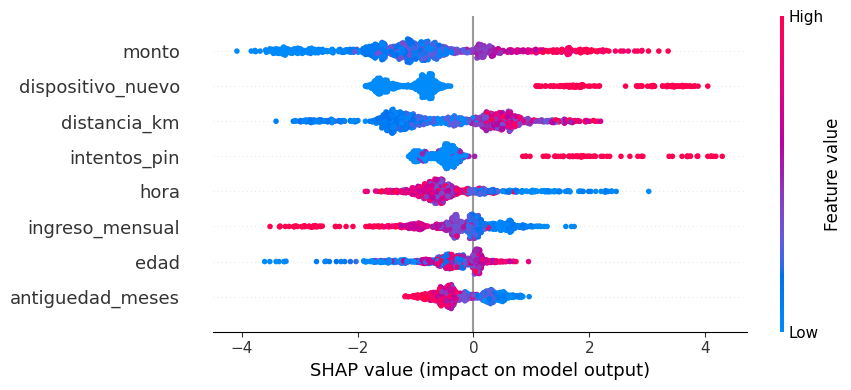

In [12]:
explicador = shap.TreeExplainer(xgb)                        # algoritmo exacto y rápido para árboles
valores = explicador.shap_values(X_test)                    # una contribución por transacción y variable
shap.summary_plot(valores, X_test, show=False, plot_size=(9, 4)); plt.show()

### ✏️ Checkpoint 4 · ⏱ 4 min
Calcule la importancia global (**promedio del valor absoluto** de SHAP por variable) y obtenga la variable **más importante**.

In [14]:
imp_shap = pd.Series(np.abs(valores).mean(axis=0), index=curso.X_COLS).sort_values(ascending=False)   # ✏️
print(imp_shap.round(3))
top = imp_shap.idxmax()
curso.checkpoint(4, top)

monto                1.379
dispositivo_nuevo    1.302
distancia_km         0.967
intentos_pin         0.689
hora                 0.675
ingreso_mensual      0.525
edad                 0.474
antiguedad_meses     0.442
dtype: float32
✅ Checkpoint 4 correcto · código K4-79B5


{'edad': 39.0, 'antiguedad_meses': 10.0, 'ingreso_mensual': 474.88, 'monto': 157.73, 'hora': 20.0, 'distancia_km': 16.0, 'intentos_pin': 1.0, 'dispositivo_nuevo': 1.0}


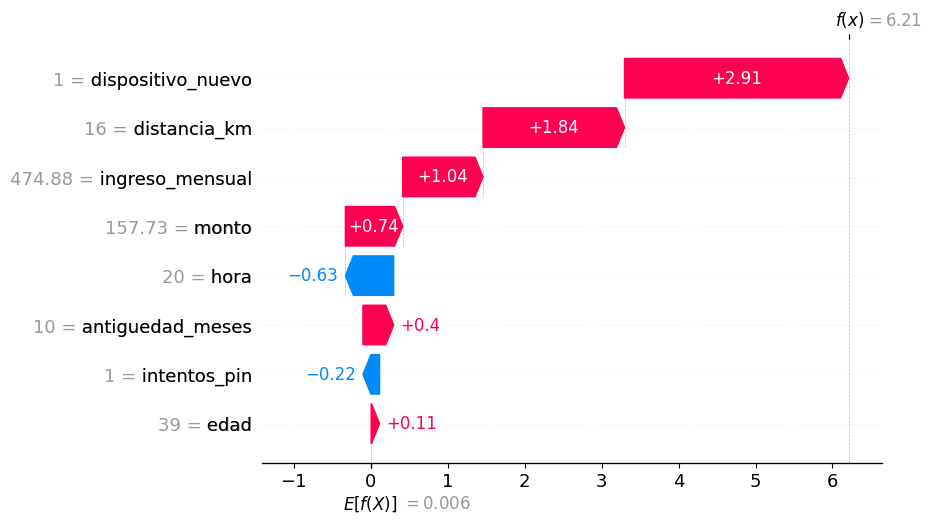

In [15]:
i = int(np.argmax(xgb.predict_proba(X_test)[:, 1]))          # la transacción con mayor probabilidad de fraude
print(X_test.iloc[i].to_dict())
shap.plots.waterfall(explicador(X_test.iloc[[i]])[0], show=False); plt.show()   # explicación de UN caso

### 💬 Pregunta 2
Con el gráfico de cascada de la transacción más sospechosa: ¿qué variables la llevaron al puntaje de fraude? ¿Para qué le sirve esto a una institución financiera?

**Respuesta:** ___

---
## 2.4 Probabilidad bayesiana: de la prior a la posterior
**Teorema de Bayes**: P(A | B) = P(B | A) · P(A) / P(B). Actualiza una creencia previa (**prior**) con la evidencia (**verosimilitud**) para obtener la creencia final (**posterior**).

**Caso 1 — alerta de fraude.** Un sistema detecta el 90 % de los fraudes (sensibilidad) y solo da falsa alarma en el 5 % de las transacciones normales (especificidad 95 %). Si salta una alerta, ¿cuál es la probabilidad de que sea fraude?

### ✏️ Checkpoint 5 · ⏱ 5 min
Aplique el teorema de Bayes con `p` = tasa de fraude de PagoYa, `sens = 0.90` y `esp = 0.95`.

In [16]:
p, sens, esp = y.mean(), 0.90, 0.95
p_alerta = sens * p + (1 - esp) * (1 - p)                    # probabilidad total de que salte una alerta
p_fraude_dado_alerta = sens * p / p_alerta                 # ✏️ teorema de Bayes
print(f'P(fraude | alerta) = {p_fraude_dado_alerta:.1%}')
curso.checkpoint(5, p_fraude_dado_alerta)

P(fraude | alerta) = 62.4%
✅ Checkpoint 5 correcto · código K5-DE2E


**Caso 2 — modelo beta-binomial.** ¿Cuál es la tasa de fraude en **Imbabura**, donde hay pocas transacciones? Prior: **Beta(a = 2, b = 20)** (media 9 %, nuestra experiencia nacional). Con k fraudes en n transacciones, la posterior es **Beta(a + k, b + n − k)** y su media es **(a + k) / (a + b + n)**.

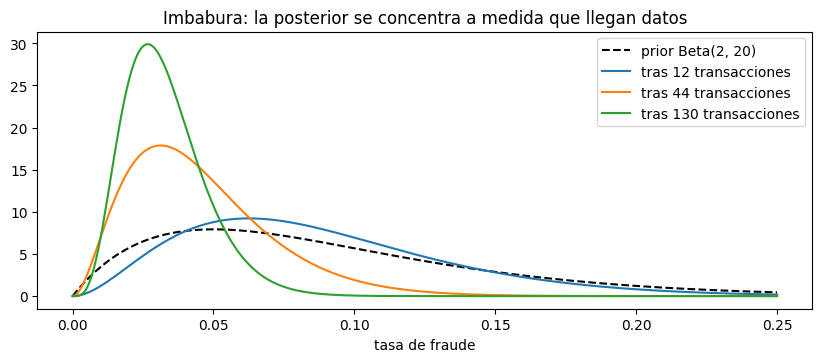

In [17]:
a, b = 2, 20                                                # prior: media a/(a+b) = 9,1 %
semanas = df.assign(semana=df['timestamp'].dt.isocalendar().week).query("provincia == 'Imbabura'")
x = np.linspace(0, 0.25, 300)
plt.plot(x, stats.beta.pdf(x, a, b), 'k--', label='prior Beta(2, 20)')
k_acum = n_acum = 0
for i, (sem, g) in enumerate(semanas.groupby('semana')):    # actualización SECUENCIAL semana a semana
    k_acum += g['fraude'].sum(); n_acum += len(g)
    if i in (0, 3, 8):
        plt.plot(x, stats.beta.pdf(x, a + k_acum, b + n_acum - k_acum), label=f'tras {n_acum} transacciones')
plt.legend(); plt.title('Imbabura: la posterior se concentra a medida que llegan datos'); plt.xlabel('tasa de fraude'); plt.show()

### ✏️ Checkpoint 6 · ⏱ 5 min
Con **todas** las transacciones de Imbabura, calcule la **media posterior** de la tasa de fraude.

In [19]:
imb = df[df['provincia'] == 'Imbabura']
k, n = imb['fraude'].sum(), len(imb)
media_post = (a + k) / (a + b + n)                           # ✏️ media de la Beta posterior
ic = stats.beta.ppf([0.025, 0.975], a + k, b + n - k)       # intervalo creíble del 95 %
print(f'Tasa observada {k/n:.1%} · media posterior {media_post:.1%} · IC 95 % [{ic[0]:.1%}, {ic[1]:.1%}]')
curso.checkpoint(6, media_post)

Tasa observada 2.3% · media posterior 3.3% · IC 95 % [1.1%, 6.6%]
✅ Checkpoint 6 correcto · código K6-E3B2


### 💬 Pregunta 3
El sistema de alertas acierta el 90 % de los fraudes, pero P(fraude | alerta) es solo ~62 %. ¿Por qué ocurre y qué implica para un equipo que revisa alertas?

**Respuesta:**
* Porque la tasa de fraude es baja 8.4%, además como la especificidad es alta (95%) hay un 5% de falsas alarmas que afecta al valor predictivo final del modelo, ya qu estas falsas alamras son aplicadas sobre la mayoría de transacciones legítimas.

* Implica que hay muchos falsos positivos en los resultados, específicamente el 37.6%. Para el equipo de revisión tener que revisar y realizar un proceso de validación.

---
## Cierre de la clase

In [20]:
curso.resumen(total=7)                                      # avance de checkpoints

Estudiante: Jair Cobos · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) (hasta las 22:30).


**Para terminar:**
1. Revise que todos los checkpoints tengan ✅ y que las 3 preguntas 💬 tengan respuesta.
2. **Archivo → Guardar (Ctrl+S)** → en *Repositorio* cambie a **el suyo**: `su-usuario/diplomado-m6-apellido` → ruta `talleres/clase2.ipynb` → mensaje `Clase 2` → Aceptar.
3. En su repositorio, pestaña **Actions**: espere el círculo verde ✅.